# Práctica 4: Umbralización

En esta práctica vamos a programar algunos de los algoritmos vistos en clase sobre umbralización. El objetivo es seguir afianzando los conocimientos de programación y tener una visión más clara sobre qué hace cada uno de los algoritmos vistos en clase

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

#### Funciones auxiliares
Uso `matplotlib` para ver las imágenes dentro del propio notebook (así no se queda colgado `cv2.waitKey`). Si prefieres `cv2.imshow`, funciona igual.

`histograma` devuelve un vector de 256 posiciones: `h[i]` = nº de píxeles con intensidad `i`. Es la base de todos los métodos globales.

In [2]:
def mostrar(imagenes, titulos, tam=(14, 4)):
    """Muestra varias imágenes en gris en una fila."""
    plt.figure(figsize=tam)
    for k, (im, t) in enumerate(zip(imagenes, titulos)):
        plt.subplot(1, len(imagenes), k + 1)
        plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        plt.title(t); plt.axis('off')
    plt.show()

def histograma(imagen):
    # Equivalente a cv2.calcHist([imagen],[0],None,[256],[0,256]).ravel()
    return np.bincount(imagen.ravel(), minlength=256).astype(np.float64)

### Ejercicio 1: mínimo entre máximos

El primer programa que vamos a implementar es la umbralización de mínimo entre máximos. Para ello, crea una función que reciba como parámetro de entrada una imagen. El programa obtendrá el histograma de la imagen. A partir del histograma es muy sencillo obtener la posición que ocupa el máximo global del histograma (recuerda la función argmax). El siguiente paso es encontrar el segundo pico del histograma. Recuerda que no es tan sencillo como buscar el segundo máximo del histograma, sino que tenemos que recorrer cada una de las intensidades:
- calcular el pico del histograma $q_1=\arg \max_i h(i)$
- para cada intensidad i:
    - Calcular $h(i)\times |i-q_1|$
- tomar como $q_2$  la posición que maximice la expresión anterior

Una vez localizados $q_1,q_2$, busca el mínimo del histograma entre ambos picos ($q_2$ puede quedar a la izquierda o a la derecha de $q_1$). Umbraliza la imagen utilizando dicho umbral. Recuerda que puedes hacer algo como
 $$umbralizada = 255*(imagen<=q).astype(np.uint8)$$
 

**Idea:** el histograma de una imagen objeto/fondo debería tener dos "montañas". El umbral es el valle (mínimo) entre las dos cimas.

- $q_1$ = el pico más alto → `argmax(h)`.
- $q_2$: no vale el 2º valor más alto, porque estaría pegado a $q_1$ (en la misma montaña). Por eso se pondera por la distancia: $h(i)\cdot|i-q_1|$ favorece intensidades altas **y** lejos de $q_1$.
- $q$ = mínimo de `h` entre ambos picos. `np.argmin` devuelve el **primer** mínimo si hay empate.

In [3]:
def min_entre_max(imagen, devolver_umbral=False):
    h = histograma(imagen)
    intensidades = np.arange(256)

    # 1) Primer pico: máximo global del histograma
    q1 = np.argmax(h)

    # 2) Segundo pico: maximiza h(i)*|i - q1|
    q2 = np.argmax(h * np.abs(intensidades - q1))

    # 3) Mínimo del histograma entre los dos picos (q2 puede estar a izq. o dcha.)
    a, b = min(q1, q2), max(q1, q2)
    q = a + np.argmin(h[a:b + 1])   # sumamos 'a' porque argmin da la posición dentro del trozo

    umbralizada = 255 * (imagen <= q).astype(np.uint8)
    if devolver_umbral:
        return umbralizada, q
    return umbralizada

Una vez programada llama a la función con la imagen 01.bmp. Si devuelves el primer mínimo que encuentres, deberías tener como umbral $q=56$ ¿Obtienes un buen resultado? ¿Por qué? ¿Qué pegas encuentras?

q1 = 53  q2 = 253  umbral q = 56


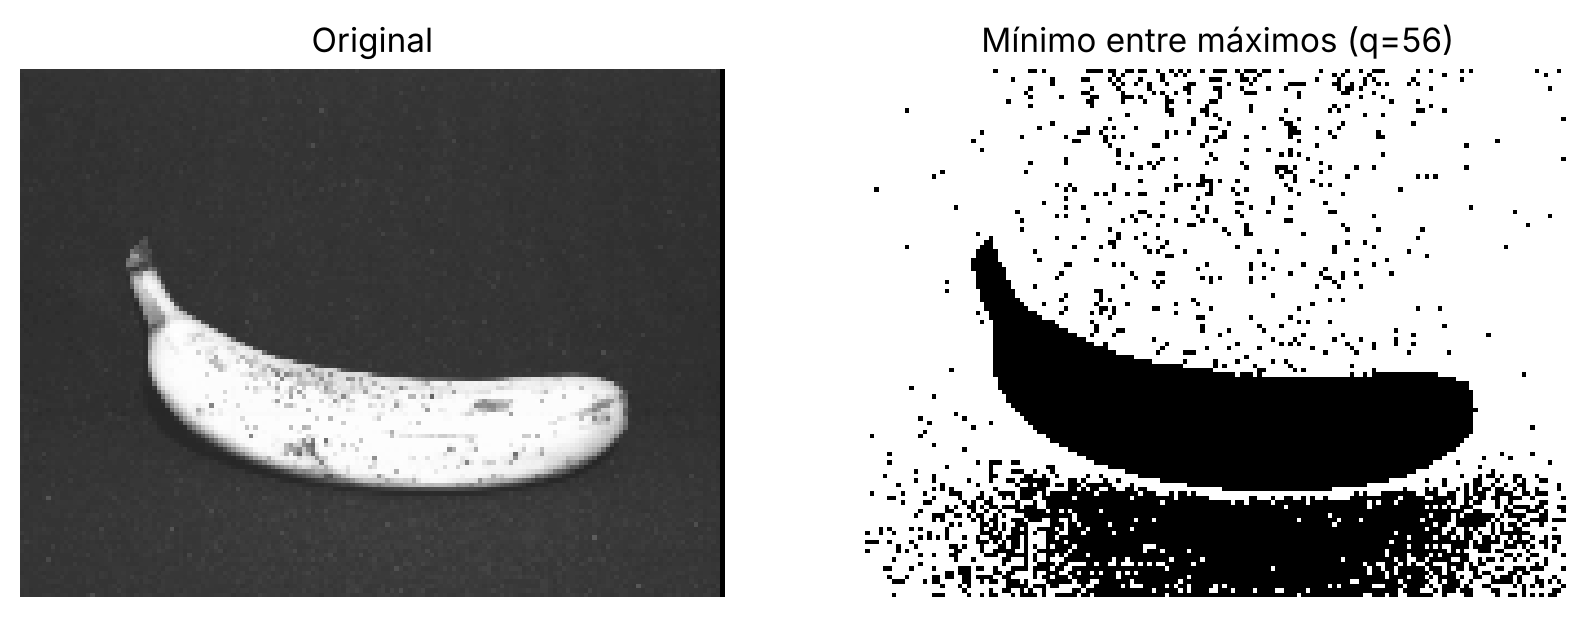

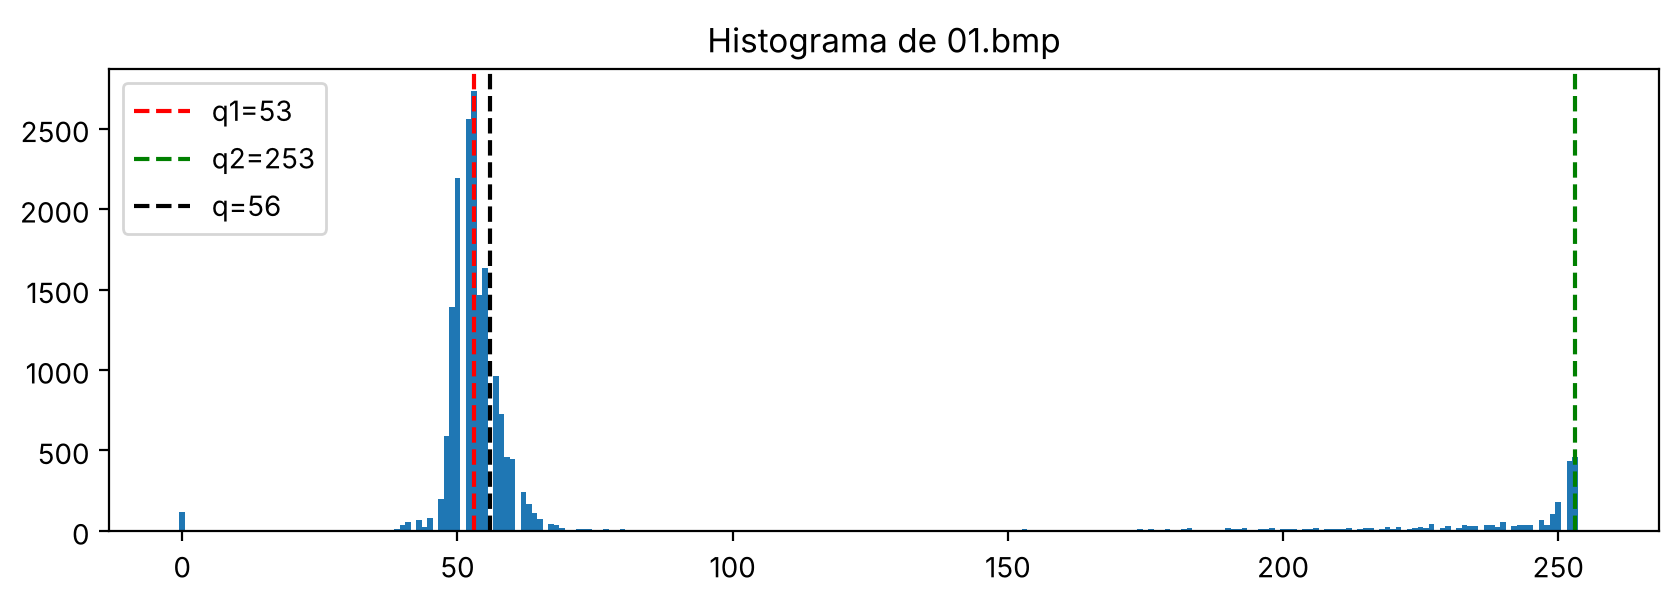

In [4]:
imagen = cv2.imread('images/01.bmp', 0)
umbralizada, q = min_entre_max(imagen, devolver_umbral=True)
h = histograma(imagen)
q1 = np.argmax(h); q2 = np.argmax(h * np.abs(np.arange(256) - q1))
print('q1 =', q1, ' q2 =', q2, ' umbral q =', q)

mostrar([imagen, umbralizada], ['Original', f'Mínimo entre máximos (q={q})'], tam=(10, 4))

plt.figure(figsize=(10, 3))
plt.bar(range(256), h, width=1)
for x, c, n in [(q1, 'r', 'q1'), (q2, 'g', 'q2'), (q, 'k', 'q')]:
    plt.axvline(x, color=c, ls='--', label=f'{n}={x}')
plt.legend(); plt.title('Histograma de 01.bmp'); plt.show()

**Respuesta:** No, el resultado no es bueno. Motivos:

- El fondo es oscuro (pico $q_1=53$) y el plátano claro ($q_2=253$): los picos están bien. El fallo está en el **mínimo**.
- El histograma **tiene mucho ruido** (forma de "peine", con barras vacías entre medias). Entre 53 y 253 hay muchísimos ceros, y `argmin` coge el **primero**: q=56, pegado al pico del fondo. Así, la mitad de los píxeles del fondo (los de intensidad 54–56 o menos) quedan como objeto → el fondo sale lleno de puntos.
- El valle "de verdad" es toda la zona plana entre ~70 y ~240; cualquier umbral ahí iría bien, pero el método no sabe elegir entre tantos mínimos iguales.
- **Pegas del método:** es muy sensible al ruido del histograma, depende de que el histograma sea claramente bimodal, y un único mínimo puntual no tiene en cuenta cómo se distribuyen todos los píxeles. Se mejora suavizando el histograma (o la imagen) antes de buscar picos y valles.

### Ejercicio 2: Otsu

Realizar una función en python que implemente el algoritmo de Otsu. Para ello, vamos a crear un array vacío de 256 posiciones. En la posición q-ésima del vector almacenaremos la varianza entre clases $\sigma_b(q)$ tomando como umbral el valor de intensidad q (probaremos $q=0,1,\dots,254$, para que ninguna de las dos clases quede vacía). Por último obtendremos como umbral aquel asociado a la máxima varianza entre clases. Recuerda que para calcular la varianza entre clases dado q debemos calcular:
- $p_0$: probabilidad de la clase 0
- $p_1$: probabilidad de la clase 1
- $\mu_0$: media de la clase 0
- $\mu_1$: media de la clase 1
- varianza entre clases: $\sigma_b^2(q)=p_0p_1(\mu_0- \mu_1)^2$

Estos cálculos se pueden hacer de dos maneras distintas. Una opción sería utilizando funciones de numpy como np.mean, etc. Otra opción sería utilizar el histograma de la imagen y calcular $p_0,p_1,\mu_0,\mu_1$ utilizando únicamente el histograma. Puedes elegir aquella que te resulte más sencilla.

**Idea de Otsu:** probar todos los umbrales $q$ y quedarse con el que **separa mejor** las dos clases, es decir, el que maximiza la varianza entre clases $\sigma_b^2$ (clases con medias muy distintas y ambas con bastantes píxeles).

Con el histograma normalizado $h_p(i)=h(i)/N$:

- $p_0=\sum_{i=0}^{q} h_p(i)$, $\quad p_1 = 1-p_0$
- $\mu_0=\frac{1}{p_0}\sum_{i=0}^{q} i\,h_p(i)$, $\quad \mu_1=\frac{1}{p_1}\sum_{i=q+1}^{255} i\,h_p(i)$

Lo hago con el histograma (mucho más rápido que recorrer la imagen 255 veces).

In [5]:
def otsu(imagen, devolver_umbral=False):
    h = histograma(imagen)
    hp = h / h.sum()                 # histograma normalizado (probabilidades)
    i = np.arange(256)

    varianzas = np.zeros(256)        # sigma_b^2(q) para cada q
    for q in range(255):             # q = 0..254 -> la clase 1 nunca queda vacía por definición
        p0 = hp[:q + 1].sum()
        p1 = 1 - p0
        if p0 == 0 or p1 == 0:       # alguna clase sin píxeles -> no es un umbral válido
            continue
        mu0 = (i[:q + 1] * hp[:q + 1]).sum() / p0
        mu1 = (i[q + 1:] * hp[q + 1:]).sum() / p1
        varianzas[q] = p0 * p1 * (mu0 - mu1) ** 2

    q = np.argmax(varianzas)         # umbral = máxima varianza entre clases
    umbralizada = 255 * (imagen <= q).astype(np.uint8)
    if devolver_umbral:
        return umbralizada, q
    return umbralizada

Una vez programada, prueba la umbralización con la imagen 01.bmp. Comprueba que obtienes el umbral 143.

Compara las imagenes obtenidas con el Ejercicio 1 y el Ejercicio 2. ¿Por qué crees que el resultado del Ejercicio 1 no tiene tanta calidad?

Prueba ahora a suavizar la imagen con un filtro Gaussiano (o un filtro de la media 3x3 o 5x5) y luego umbraliza con la función Otsu. ¿Obtienes alguna mejora?


Umbral Otsu: 143
Comprobación con OpenCV: 143.0


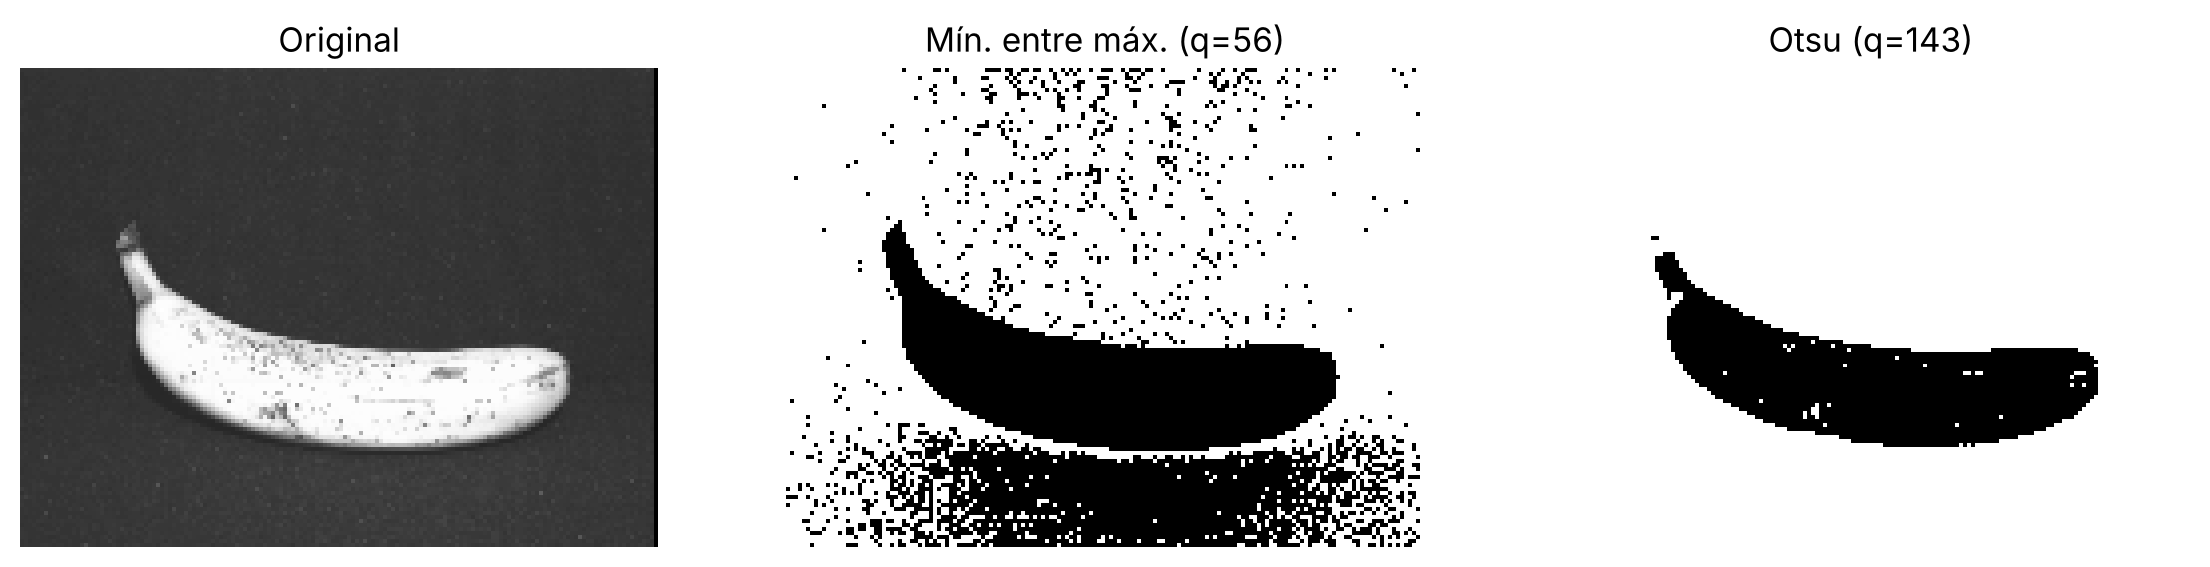

In [6]:
imagen = cv2.imread('images/01.bmp', 0)
um_otsu, q_otsu = otsu(imagen, devolver_umbral=True)
um_mm, q_mm = min_entre_max(imagen, devolver_umbral=True)
print('Umbral Otsu:', q_otsu)
print('Comprobación con OpenCV:', cv2.threshold(imagen, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0])

mostrar([imagen, um_mm, um_otsu],
        ['Original', f'Mín. entre máx. (q={q_mm})', f'Otsu (q={q_otsu})'])

**¿Por qué el Ejercicio 1 tiene peor calidad?** Mínimo entre máximos solo mira **un punto** del histograma (un mínimo local), y con un histograma ruidoso ese punto cae en un sitio que no representa la frontera real. Otsu, en cambio, usa **todo el histograma** (probabilidades y medias de cada clase), así que es mucho más robusto al ruido: pequeños picos y valles casi no cambian $\sigma_b^2$.

Ahora suavizo la imagen antes de Otsu:

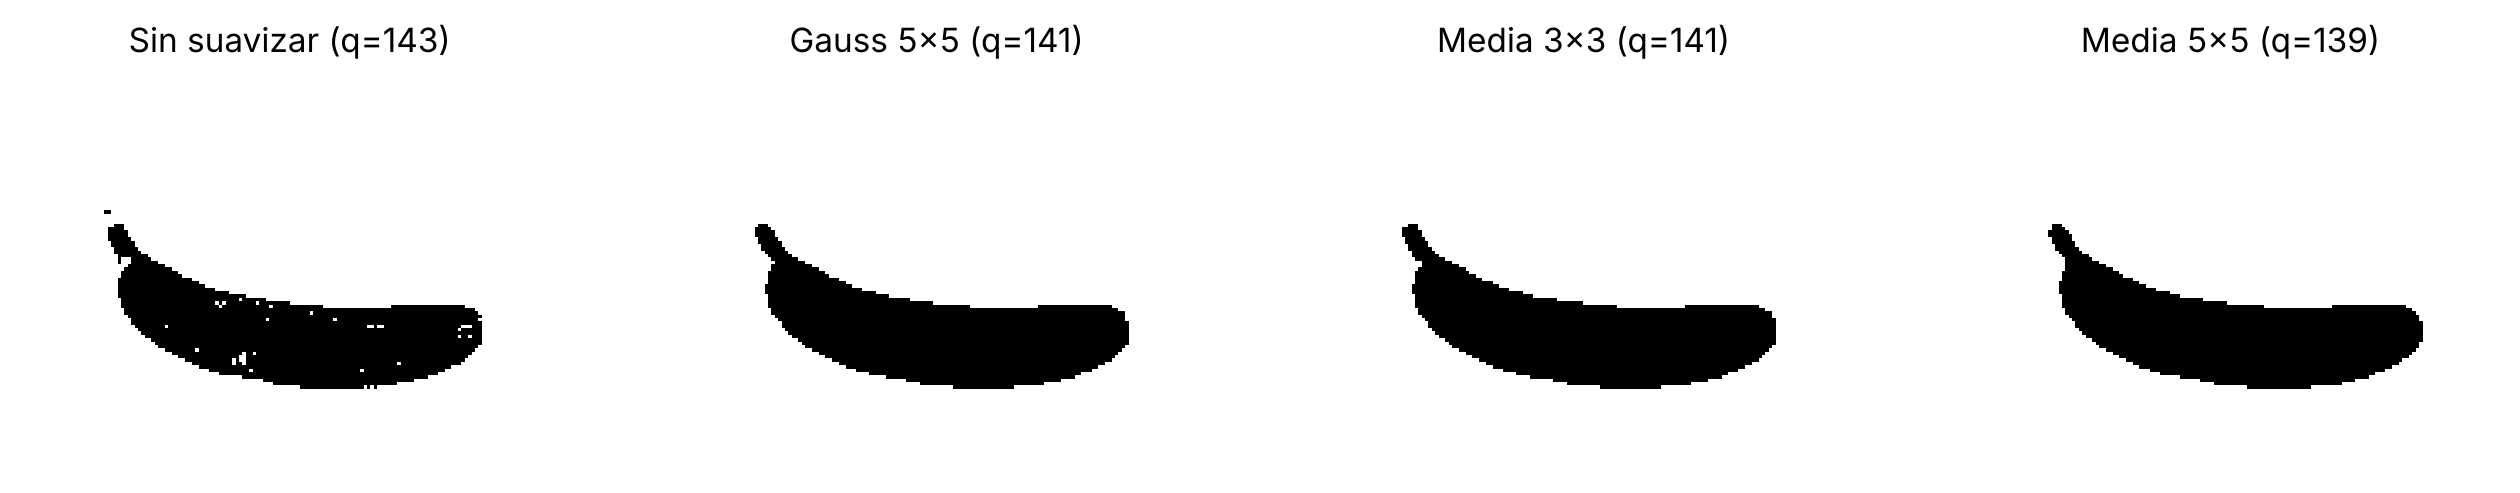

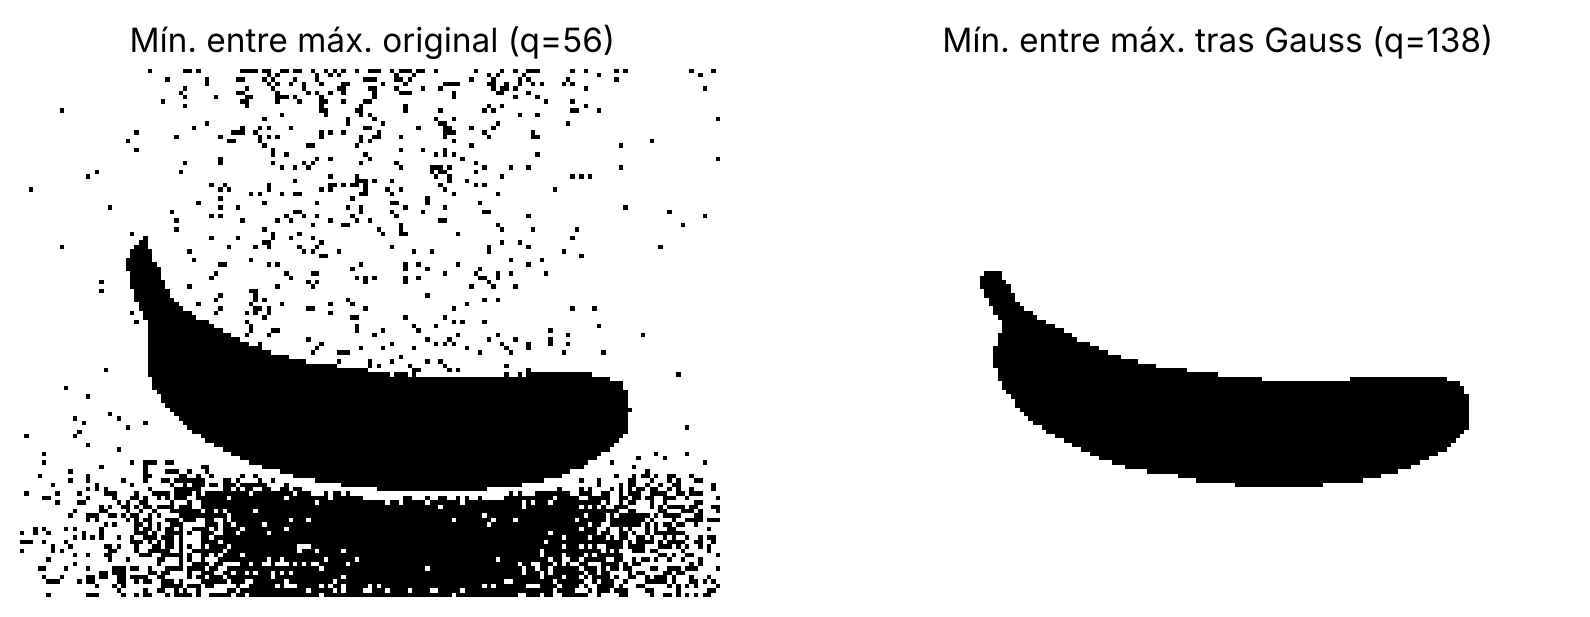

In [7]:
gauss = cv2.GaussianBlur(imagen, (5, 5), 0)
media3 = cv2.blur(imagen, (3, 3))
media5 = cv2.blur(imagen, (5, 5))

res = []
for nombre, im in [('Sin suavizar', imagen), ('Gauss 5x5', gauss), ('Media 3x3', media3), ('Media 5x5', media5)]:
    u, q = otsu(im, devolver_umbral=True)
    res.append((u, f'{nombre} (q={q})'))
mostrar([r[0] for r in res], [r[1] for r in res], tam=(16, 4))

# El suavizado también ayuda (mucho) al mínimo entre máximos:
u, q = min_entre_max(gauss, devolver_umbral=True)
mostrar([um_mm, u], [f'Mín. entre máx. original (q={q_mm})', f'Mín. entre máx. tras Gauss (q={q})'], tam=(10, 4))

**Respuesta:** Sí, hay mejora. El suavizado reduce el ruido de la imagen: desaparecen muchos píxeles sueltos mal clasificados ("sal y pimienta") y los bordes del objeto quedan más limpios y compactos. El umbral cambia poco, pero el resultado es más homogéneo. A cambio, si se suaviza demasiado (5x5 o más) se pierden detalles finos y los bordes se redondean.

### Ejercicio 3: Umbralización de mínimo error

Este algoritmo es algo parecido al anterior. Vamos a ir probando cada una de las intensidades posibles como umbral y, para cada una, calcularemos una distribución de probabilidad gaussiana según la media y la desviación de los píxeles de la clase 0 y clase 1 en función del umbral. Para ello, recorre el conjunto de intensidades y calcula:
- $p_0$: probabilidad de la clase0
- $p_1$: probabilidad de la clase1
- $\mu_0$: media de la clase 0
- $\mu_1$: media de la clase 1
- $\sigma_0^2$: varianza de la clase 0
- $\sigma_1^2$: varianza de la clase 1


Una vez tenemos los parámetros de cada una de las clases, vamos a calcular el error que cometemos al asignar cada una de las intensidades a la clase 0 y a la clase 1 en función del umbral. Esto se calcula como

$$e(q)=\sum_{i=0}^{q}h_p(i)e_0(i)+\sum_{i=q+1}^{255}h_p(i)e_1(i)$$

donde $h_p$ es el histograma normalizado y

$$e_j(i)=\frac{(i-\mu_j)^2}{\sigma_j^2}+2(\log(\sigma_j)-\log(p_j))$$

Nota: en el cálculo de las varianzas, podemos sumarle a la variable un pequeño valor (1e-10) para evitar el logaritmo de 0.

Una vez calculado el error por cada posible umbral, tomaremos aquel que minimice el error cometido.

**Idea:** modelar el histograma como la suma de dos gaussianas (una por clase). Para cada $q$ se estiman los parámetros de cada clase y se mide cómo de mal se ajusta (el error). Nos quedamos con el $q$ de menor error.

- $\sigma_j^2=\frac{1}{p_j}\sum_{i\in C_j}(i-\mu_j)^2 h_p(i)$
- $e_0$ se aplica a las intensidades $\le q$ (clase 0) y $e_1$ a las $>q$ (clase 1).

> **Nota sobre el umbral 78:** aplicando literalmente la fórmula, con $\log(\sigma_j)$ (desviación típica), sale **q = 79**. Si en el término del logaritmo se usa la **varianza** $\log(\sigma_j^2)$ sale **q = 78**, que es el valor del enunciado (seguramente la solución del profesor guarda la varianza en la variable `sigma`). La diferencia es mínima; dejo el parámetro `log_varianza` para que puedas obtener cualquiera de los dos.

In [8]:
def parametros_clases(hp, q):
    """p, mu y varianza de las clases 0 (i<=q) y 1 (i>q) a partir del histograma normalizado."""
    i = np.arange(256)
    p0 = hp[:q + 1].sum()
    p1 = 1 - p0
    mu0 = (i[:q + 1] * hp[:q + 1]).sum() / p0
    mu1 = (i[q + 1:] * hp[q + 1:]).sum() / p1
    var0 = ((i[:q + 1] - mu0) ** 2 * hp[:q + 1]).sum() / p0 + 1e-10
    var1 = ((i[q + 1:] - mu1) ** 2 * hp[q + 1:]).sum() / p1 + 1e-10
    return p0, p1, mu0, mu1, var0, var1


def minimo_error(imagen, devolver_umbral=False, log_varianza=False):
    h = histograma(imagen)
    hp = h / h.sum()
    i = np.arange(256)

    errores = np.full(256, np.inf)   # inf: así los q no válidos nunca son el mínimo
    for q in range(255):
        p0 = hp[:q + 1].sum()
        p1 = 1 - p0
        if p0 == 0 or p1 == 0:
            continue
        p0, p1, mu0, mu1, var0, var1 = parametros_clases(hp, q)

        if log_varianza:              # variante que da 78
            log_s0, log_s1 = np.log(var0), np.log(var1)
        else:                         # fórmula literal: log(sigma) = log(sqrt(var))
            log_s0, log_s1 = np.log(np.sqrt(var0)), np.log(np.sqrt(var1))

        e0 = (i - mu0) ** 2 / var0 + 2 * (log_s0 - np.log(p0))   # error de asignar i a clase 0
        e1 = (i - mu1) ** 2 / var1 + 2 * (log_s1 - np.log(p1))   # error de asignar i a clase 1

        errores[q] = (hp[:q + 1] * e0[:q + 1]).sum() + (hp[q + 1:] * e1[q + 1:]).sum()

    q = np.argmin(errores)
    umbralizada = 255 * (imagen <= q).astype(np.uint8)
    if devolver_umbral:
        return umbralizada, q
    return umbralizada

Una vez programado, comprueba su funcionamiento con las imágenes de antes y revisa si obtienes umbral 78. Al igual que aparece en las explicaciones de clase, podríamos pintar encima del histograma las dos distribuciones gaussianas que tratan de ajustarse al histograma. Para ello, una vez conocido el umbral q, las distribuciones gaussianas de la clase 0 y de la clase 1 vendrían dadas, para cada posible intensidad x, por

$$\frac{1}{\sqrt{2\pi\sigma_0^2}}*\exp\left(-\frac{(x-\mu_0)^2}{2\sigma_0^2}\right)$$
$$\frac{1}{\sqrt{2\pi\sigma_1^2}}*\exp\left(-\frac{(x-\mu_1)^2}{2\sigma_1^2}\right)$$

Umbral mínimo error (log sigma):   79
Umbral mínimo error (log sigma^2): 78


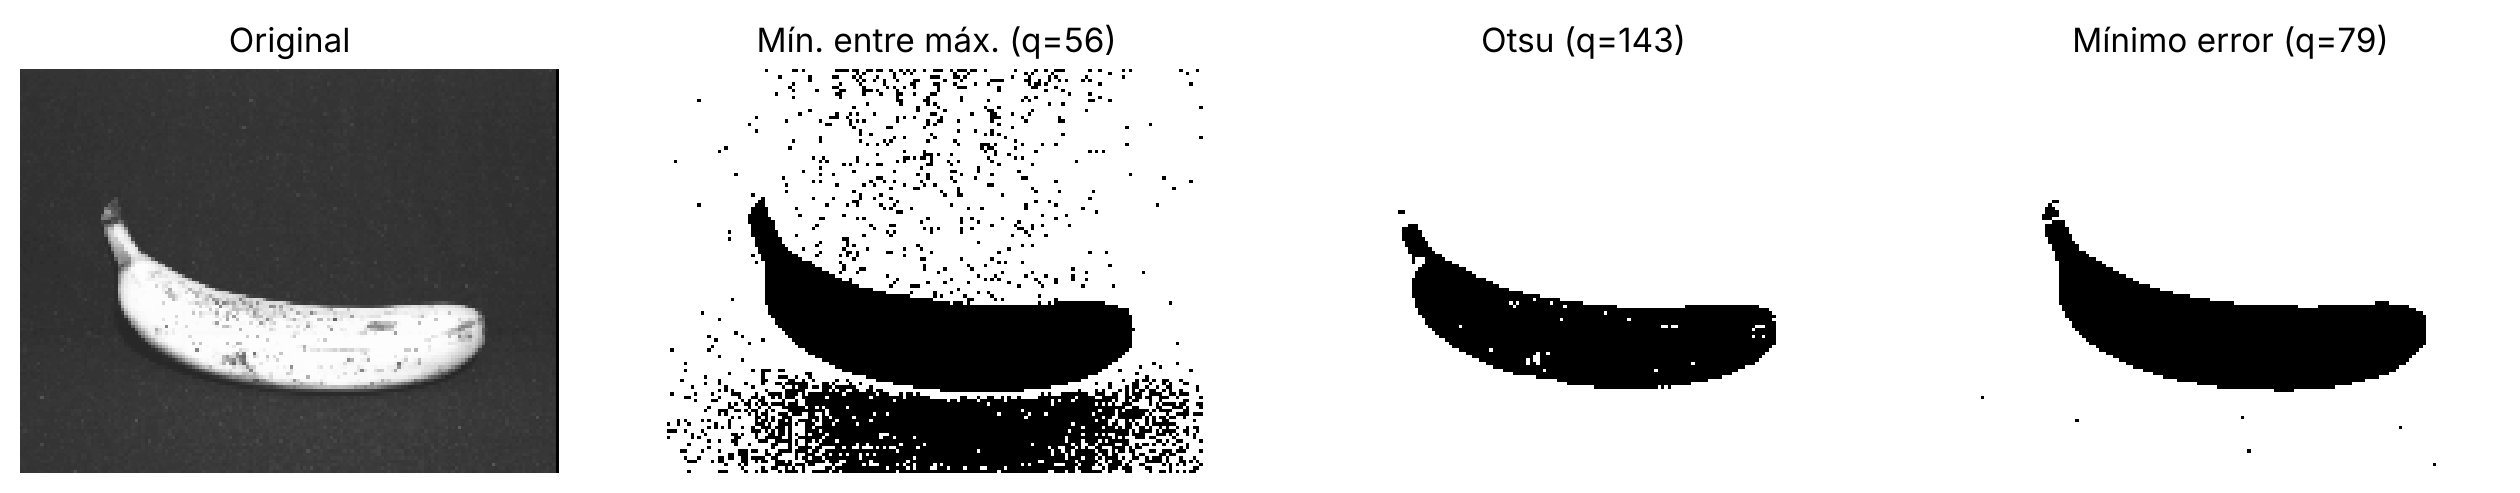

In [9]:
imagen = cv2.imread('images/01.bmp', 0)
um_me, q_me = minimo_error(imagen, devolver_umbral=True)
_, q_me_var = minimo_error(imagen, devolver_umbral=True, log_varianza=True)
print('Umbral mínimo error (log sigma):  ', q_me)
print('Umbral mínimo error (log sigma^2):', q_me_var)

mostrar([imagen, um_mm, um_otsu, um_me],
        ['Original', f'Mín. entre máx. (q={q_mm})', f'Otsu (q={q_otsu})', f'Mínimo error (q={q_me})'], tam=(16, 4))

Dibujamos las dos gaussianas (multiplicadas por $p_j$, que es lo que realmente aproxima al histograma normalizado) encima del histograma:

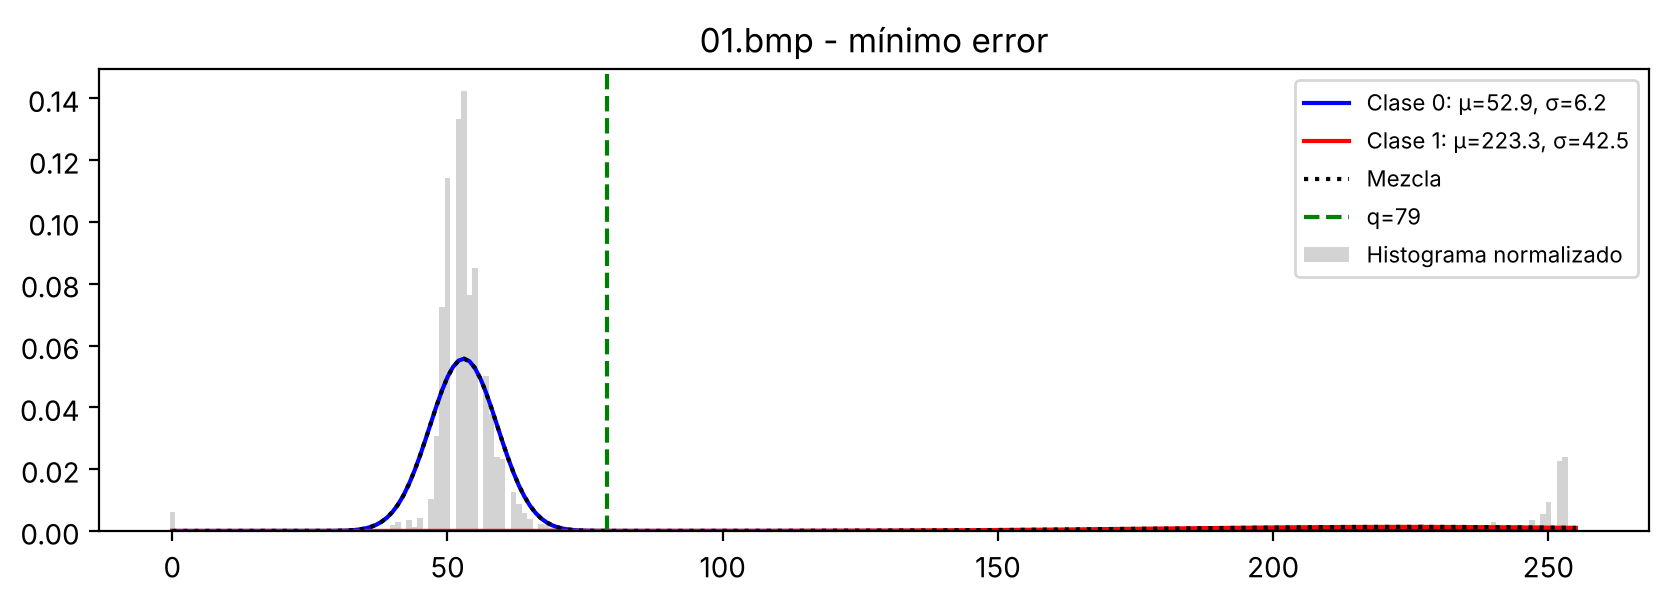

In [10]:
def dibujar_gaussianas(imagen, q, titulo=''):
    hp = histograma(imagen) / imagen.size
    p0, p1, mu0, mu1, var0, var1 = parametros_clases(hp, q)
    x = np.arange(256)
    g0 = 1 / np.sqrt(2 * np.pi * var0) * np.exp(-(x - mu0) ** 2 / (2 * var0))
    g1 = 1 / np.sqrt(2 * np.pi * var1) * np.exp(-(x - mu1) ** 2 / (2 * var1))

    plt.figure(figsize=(10, 3))
    plt.bar(x, hp, width=1, color='lightgray', label='Histograma normalizado')
    plt.plot(x, p0 * g0, 'b', label=f'Clase 0: μ={mu0:.1f}, σ={np.sqrt(var0):.1f}')
    plt.plot(x, p1 * g1, 'r', label=f'Clase 1: μ={mu1:.1f}, σ={np.sqrt(var1):.1f}')
    plt.plot(x, p0 * g0 + p1 * g1, 'k:', label='Mezcla')
    plt.axvline(q, color='g', ls='--', label=f'q={q}')
    plt.title(titulo); plt.legend(fontsize=8); plt.show()

dibujar_gaussianas(imagen, q_me, '01.bmp - mínimo error')

Probamos los tres métodos con el resto de imágenes de la carpeta:

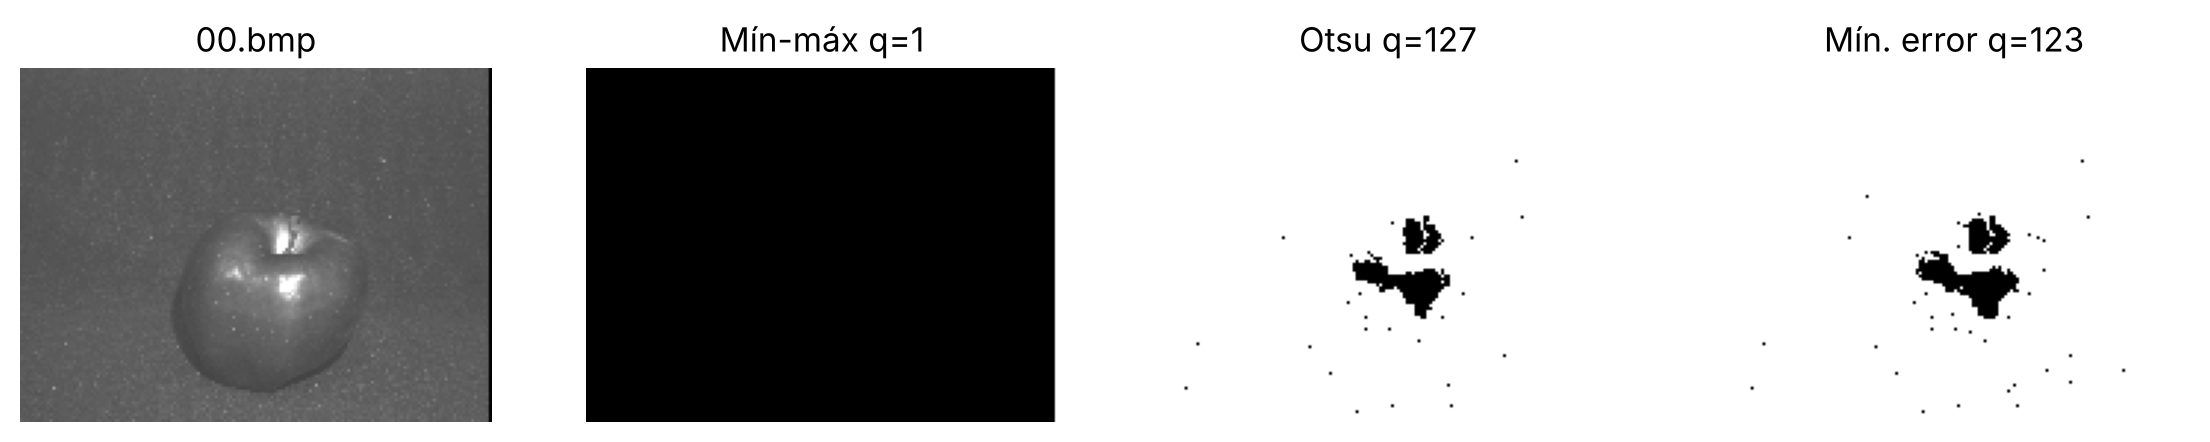

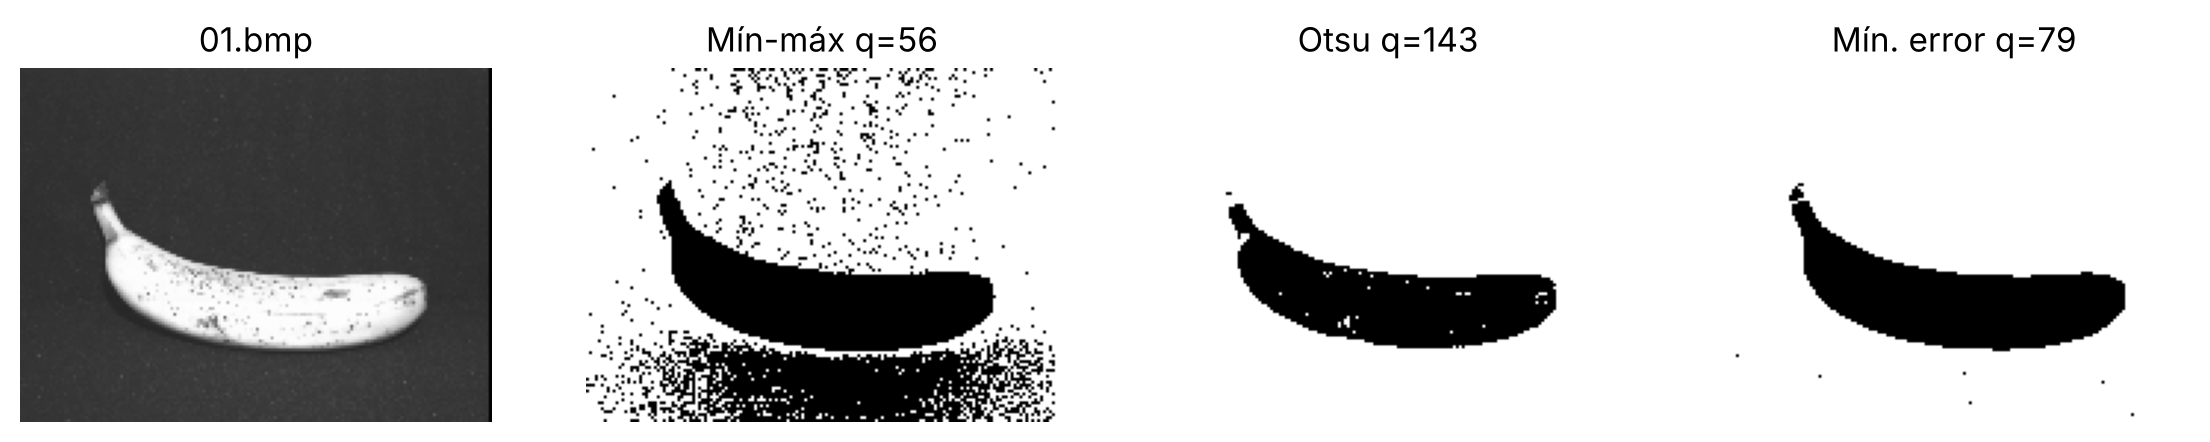

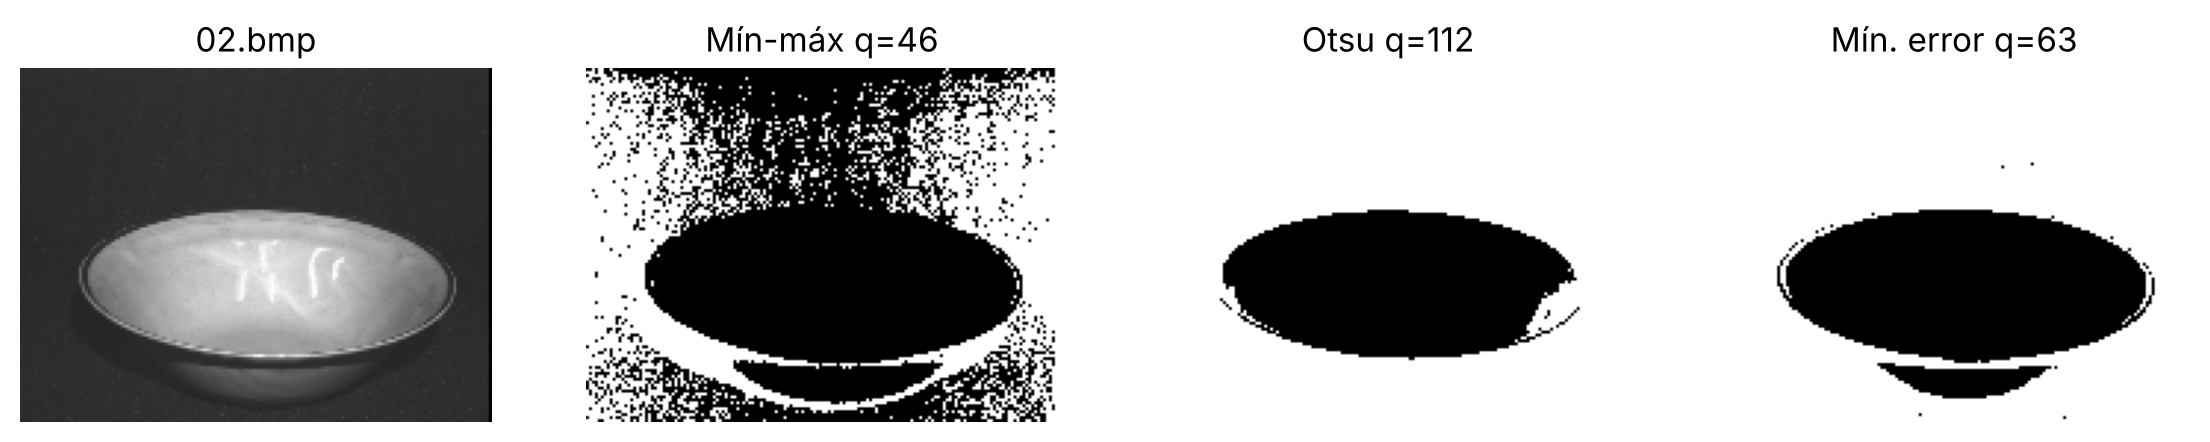

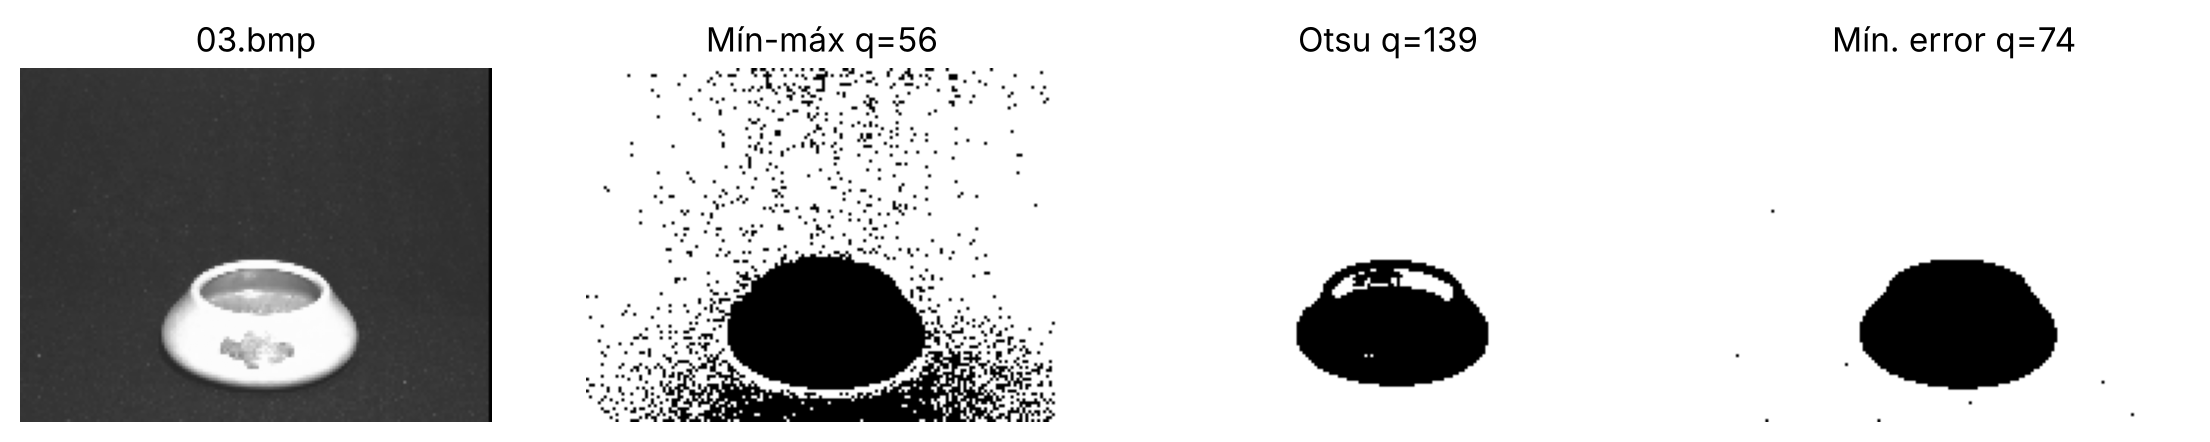

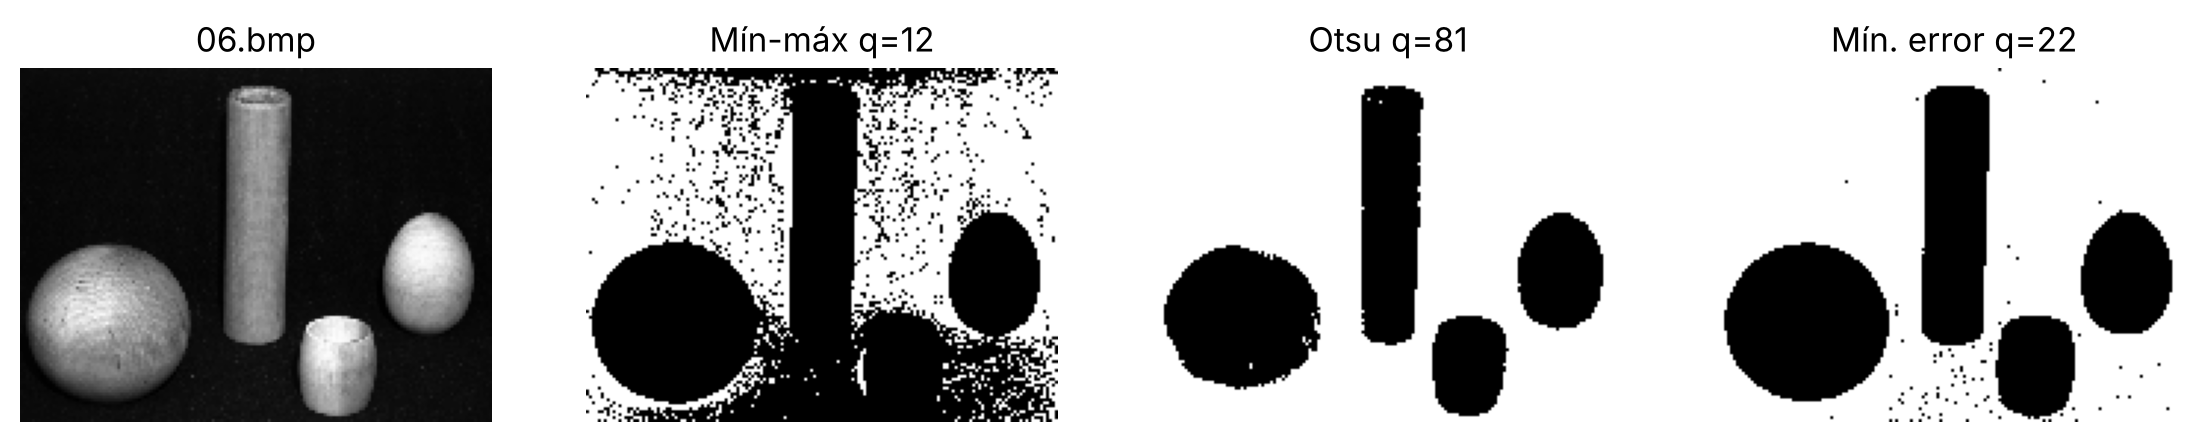

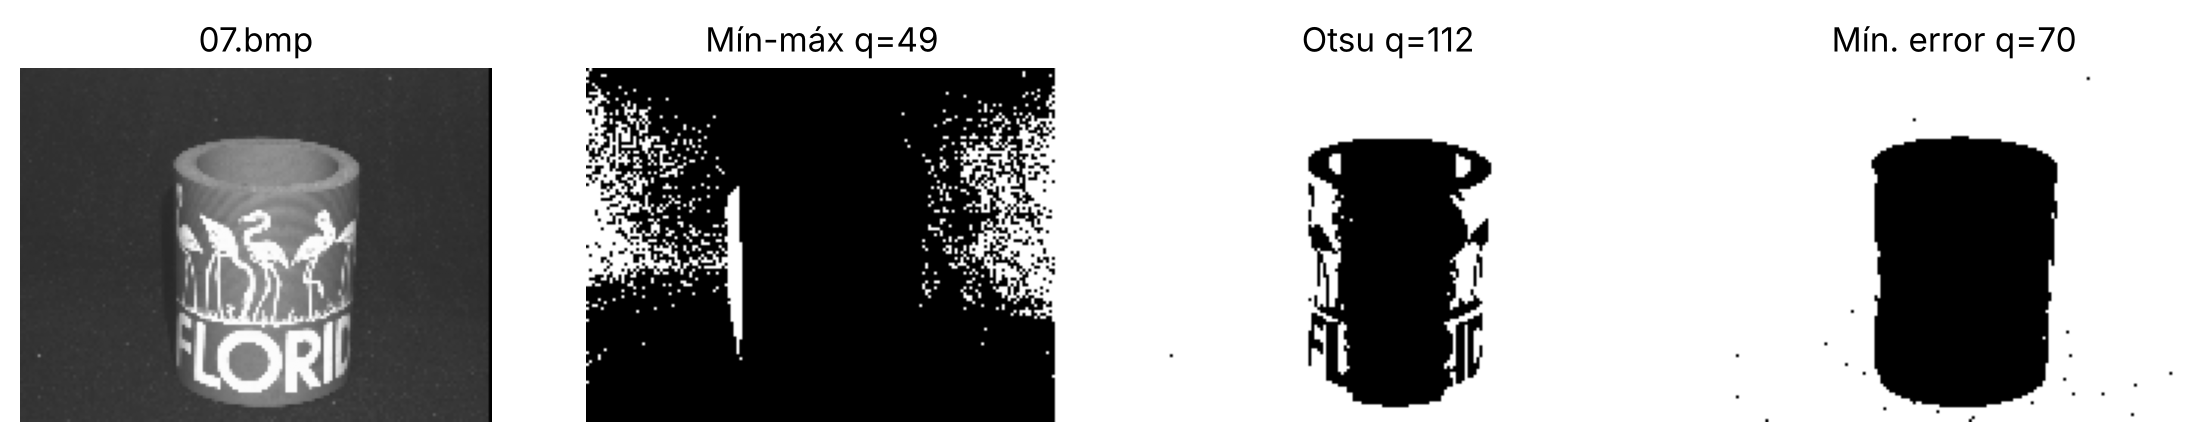

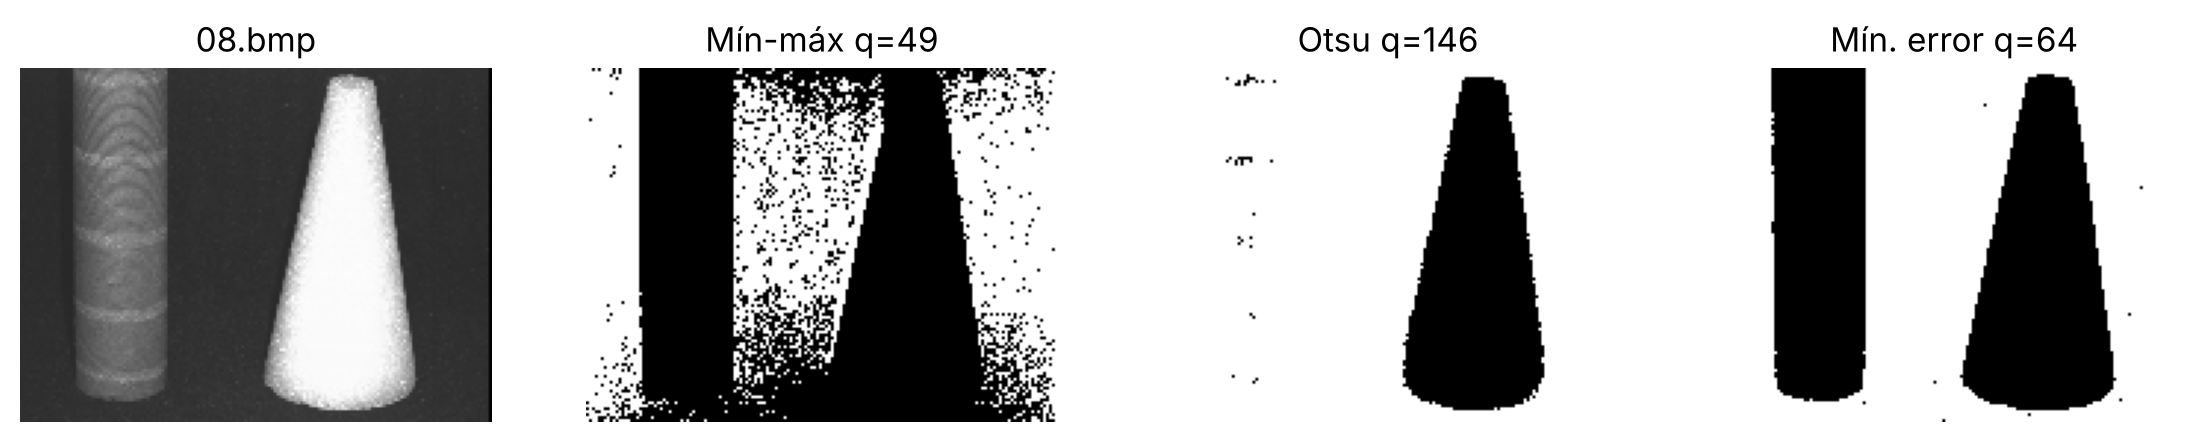

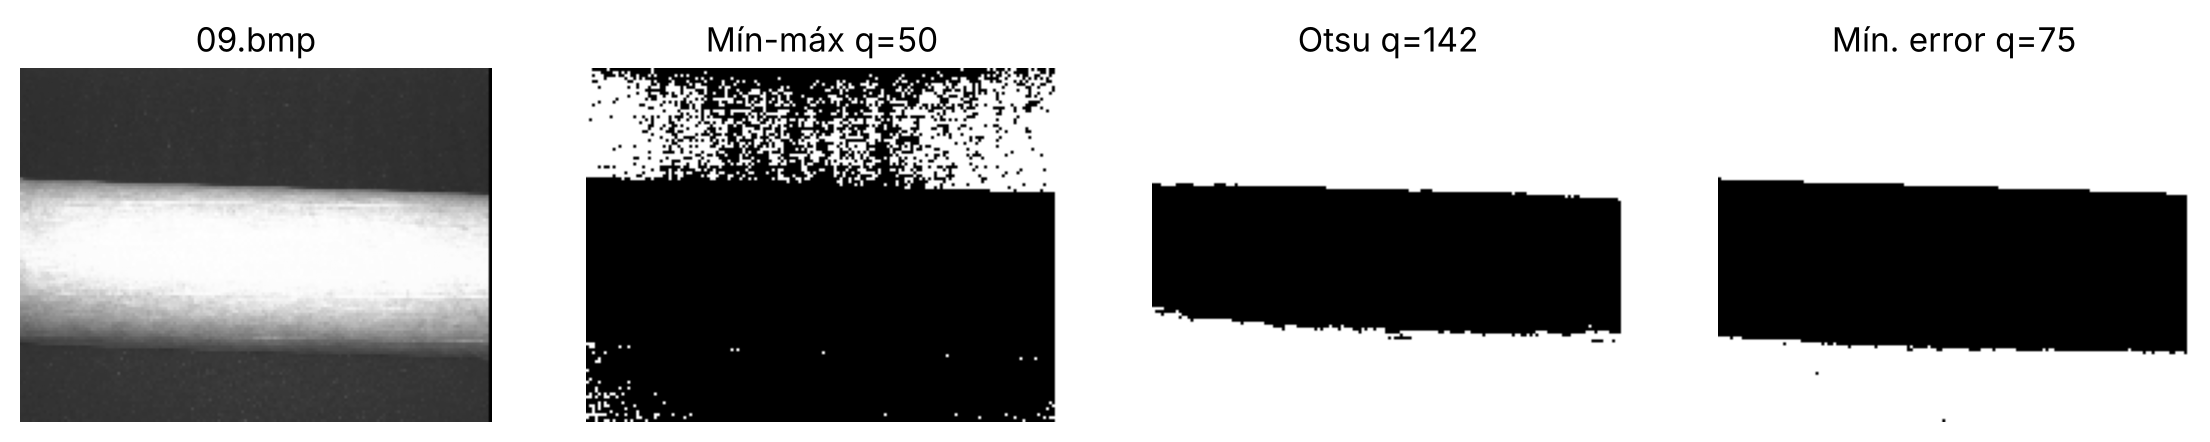

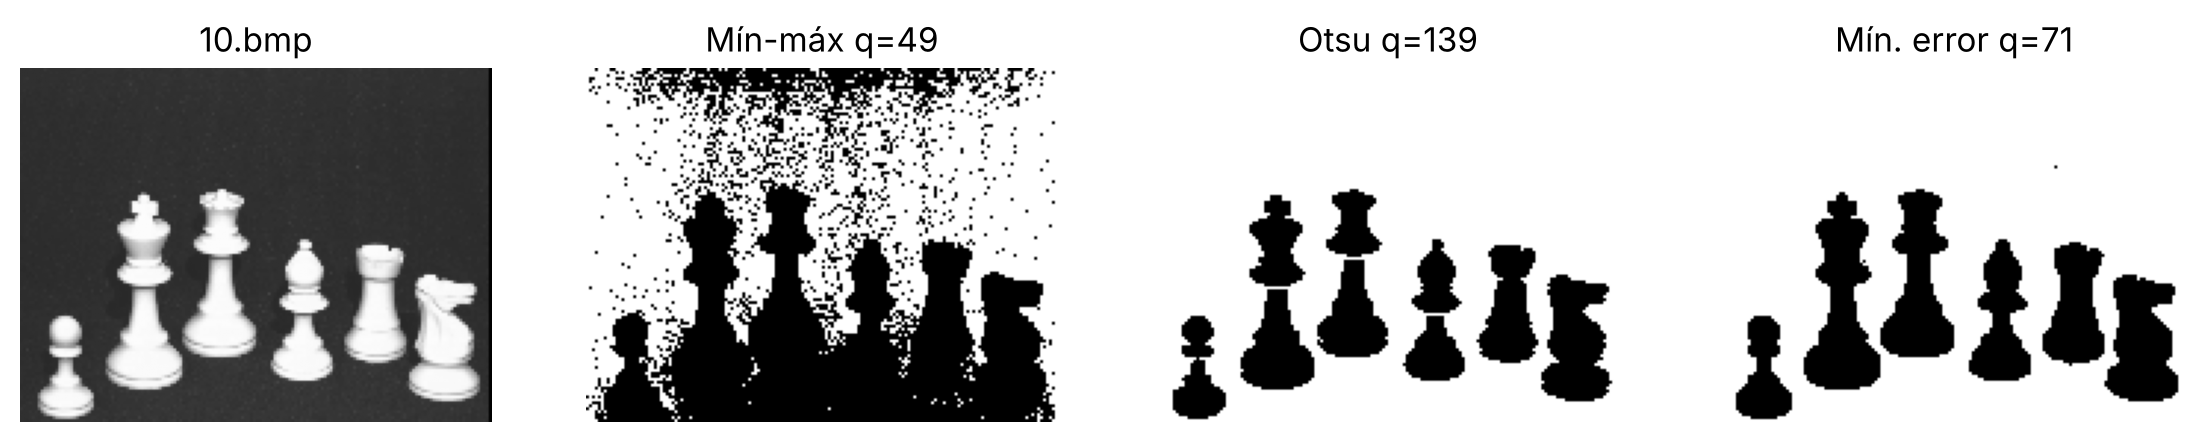

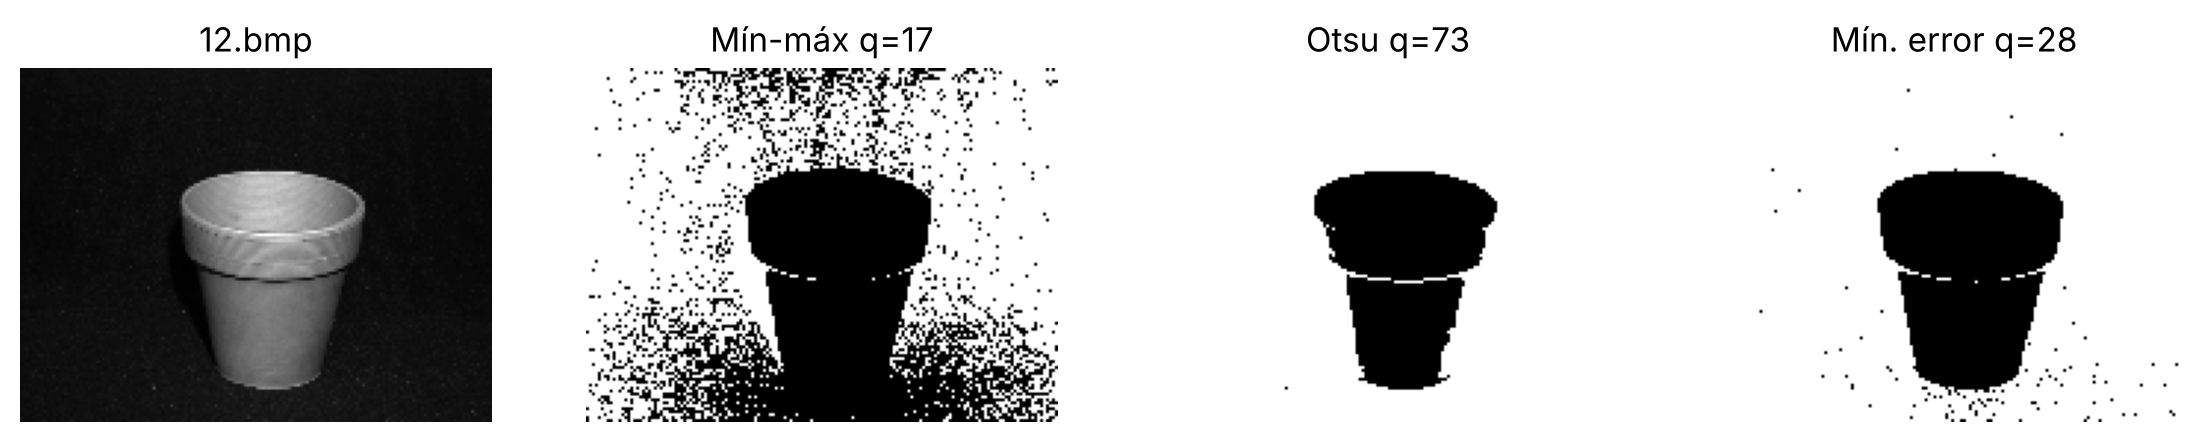

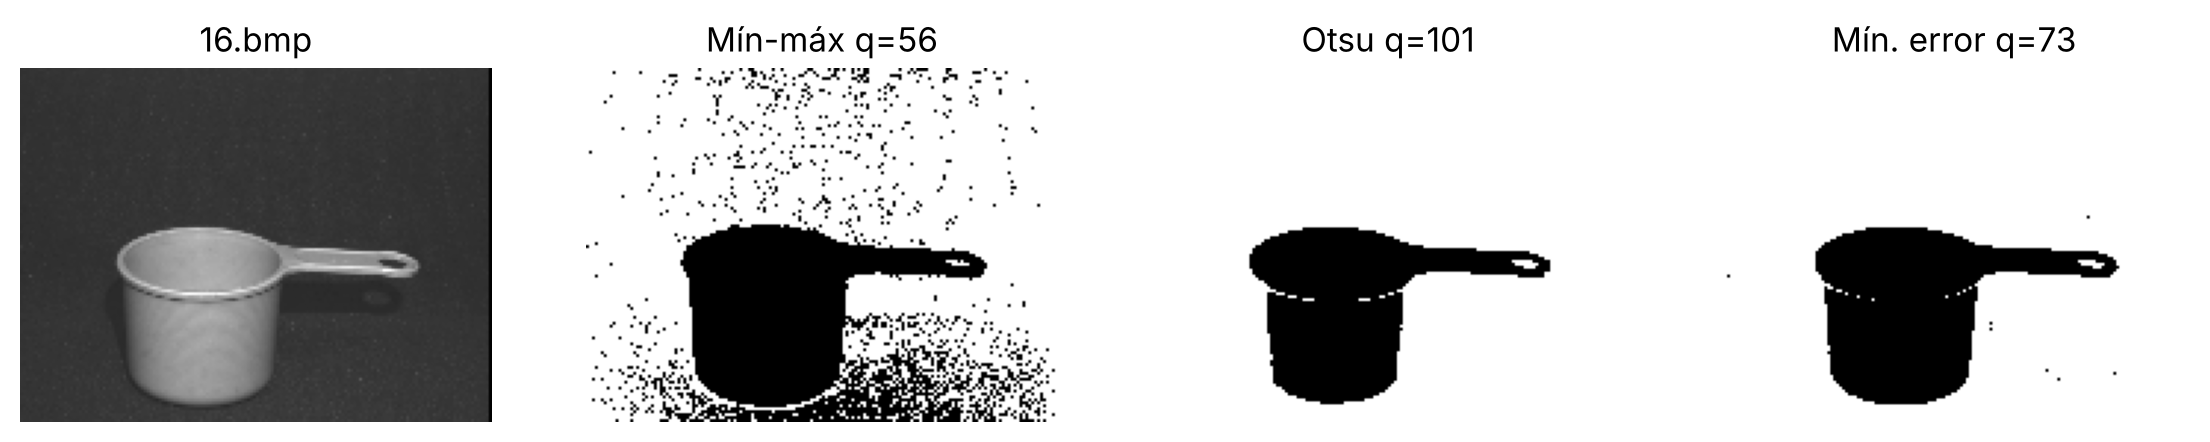

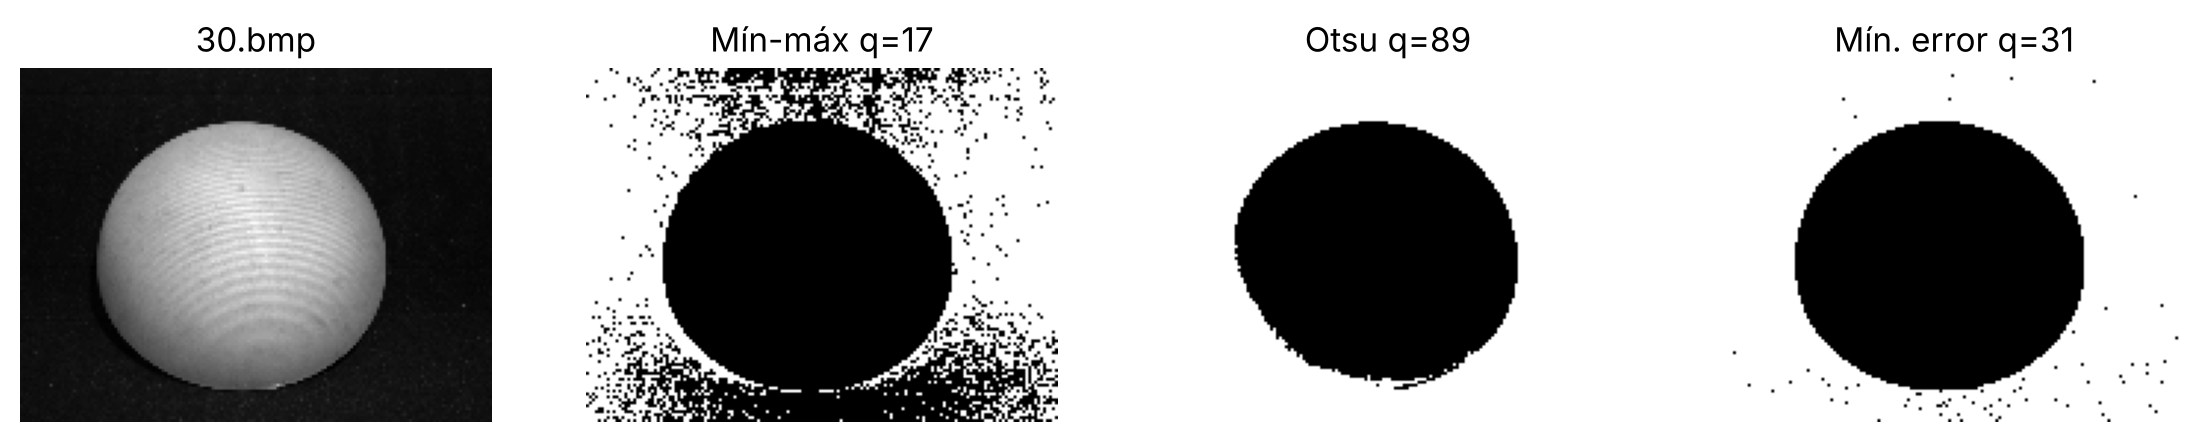

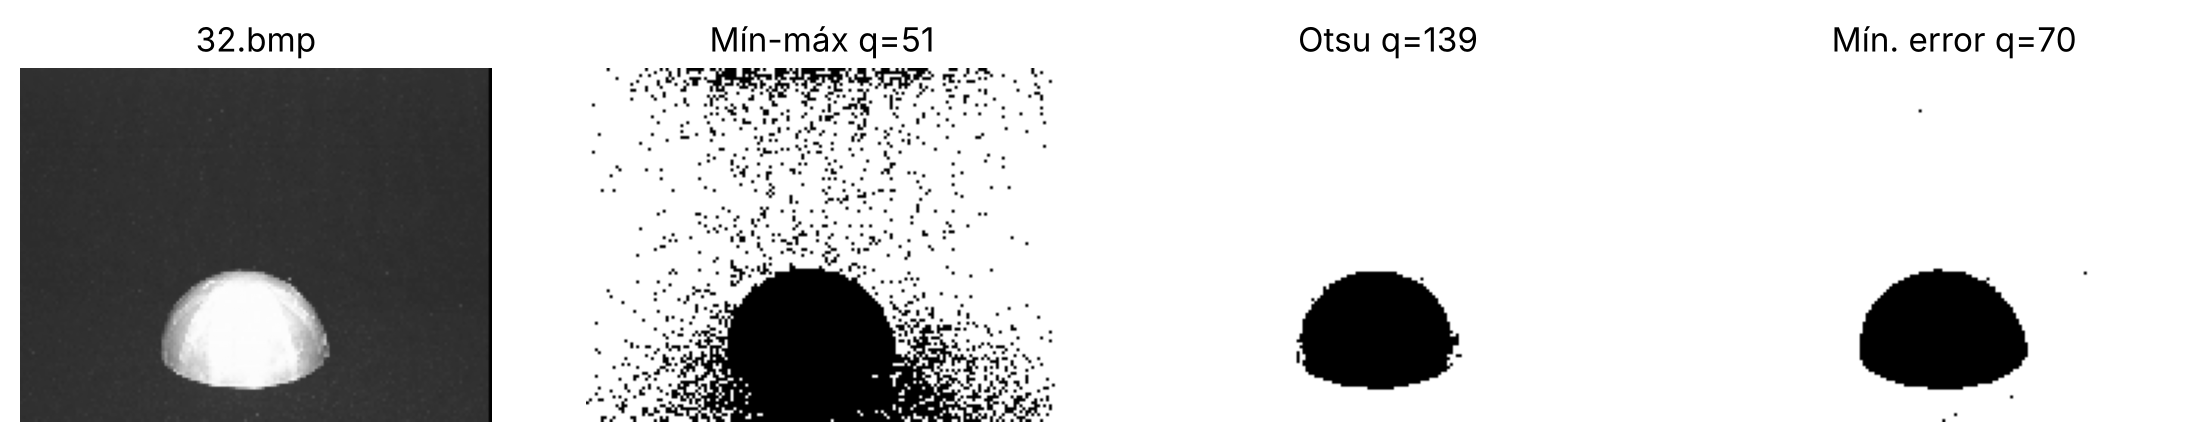

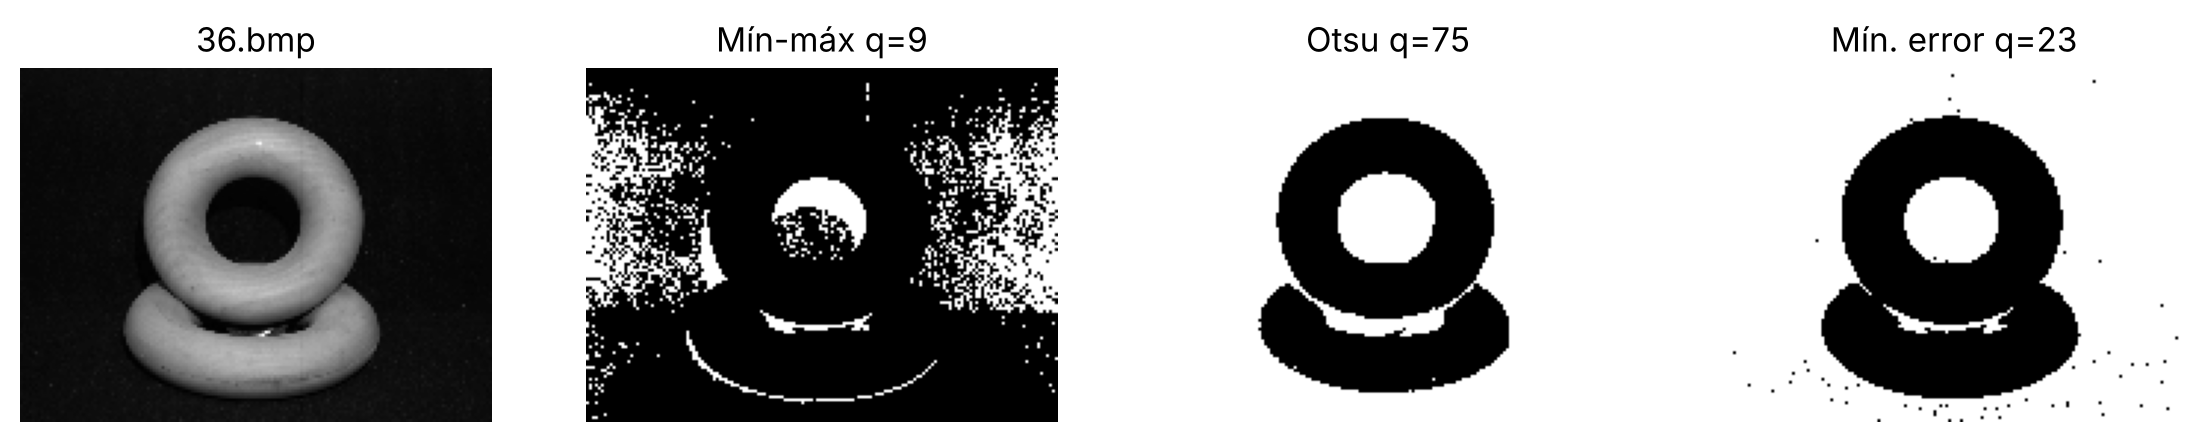

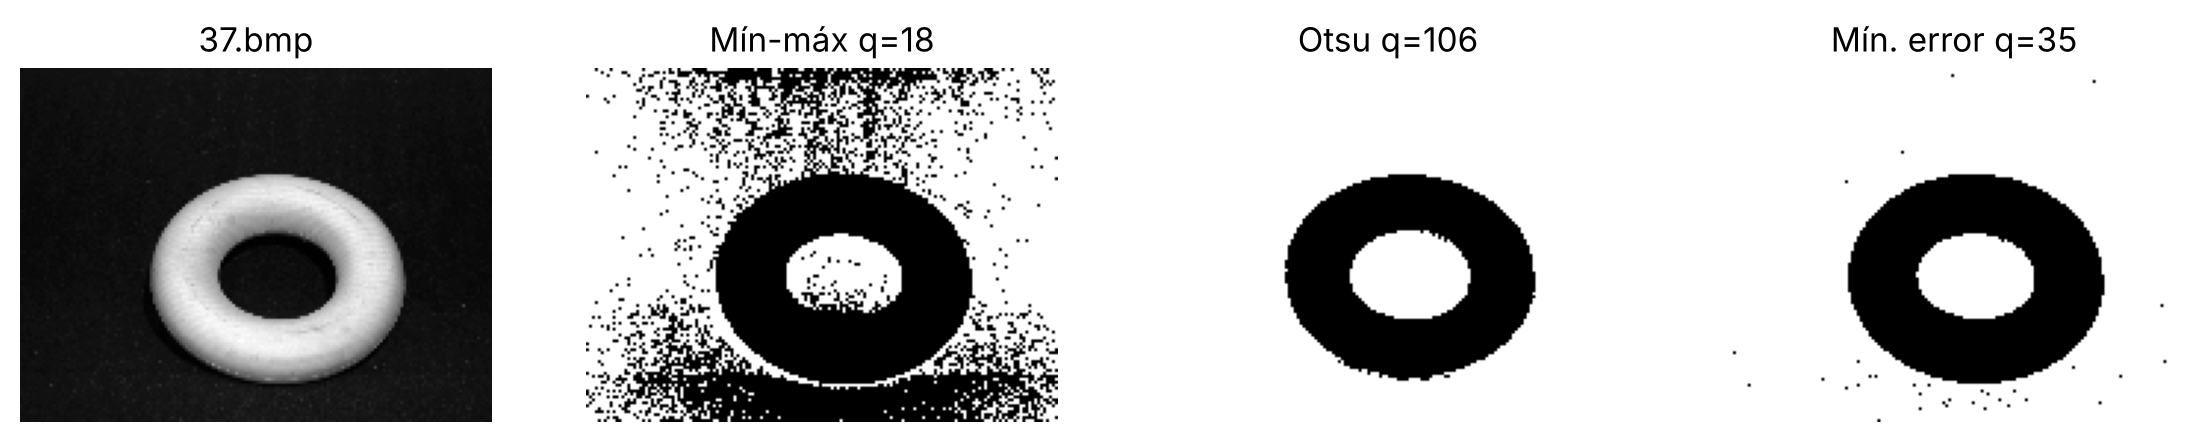

In [11]:
import os
for nombre in sorted(f for f in os.listdir('images') if f.endswith('.bmp')):
    im = cv2.imread(os.path.join('images', nombre), 0)
    a, qa = min_entre_max(im, True)
    b, qb = otsu(im, True)
    c, qc = minimo_error(im, True)
    mostrar([im, a, b, c], [nombre, f'Mín-máx q={qa}', f'Otsu q={qb}', f'Mín. error q={qc}'], tam=(14, 3))

### Ejercicio 4: Umbralización variable

Uno de los problemas del algoritmo de Otsu aparece cuando la iluminación de la imagen no es constante. Lee la imagen texto.tif. Visualiza y aplica el algoritmo del ejercicio 2 (otsu). Comprueba que la segmentación no es la adecuada. Vamos a solventar este problema mediante una umbralización variable, es decir, una combinación de técnicas globales y locales. De hecho, vamos a ver que se parece mucho a un filtro no lineal sobre la imagen. El algoritmo es el siguiente:
- para cada píxel de la imagen
    - tomar una ventana 3x3 de píxeles centrada en el
    - calcular la media aritmética $\mu_{x,y}$ y la desviación típica $\sigma_{x,y}$
    - Realizar la siguiente segmentación 
    $$g(x,y)=\begin{cases} 
        1 & \mbox{ si } imagen(x,y)<\sigma_{x,y}+0.5\mu_{x,y} \\
        0 & \mbox{ en otro caso}
    \end{cases}$$

La función debe devolver $g$ como una imagen de tipo np.uint8 (con valores 0 y 1).

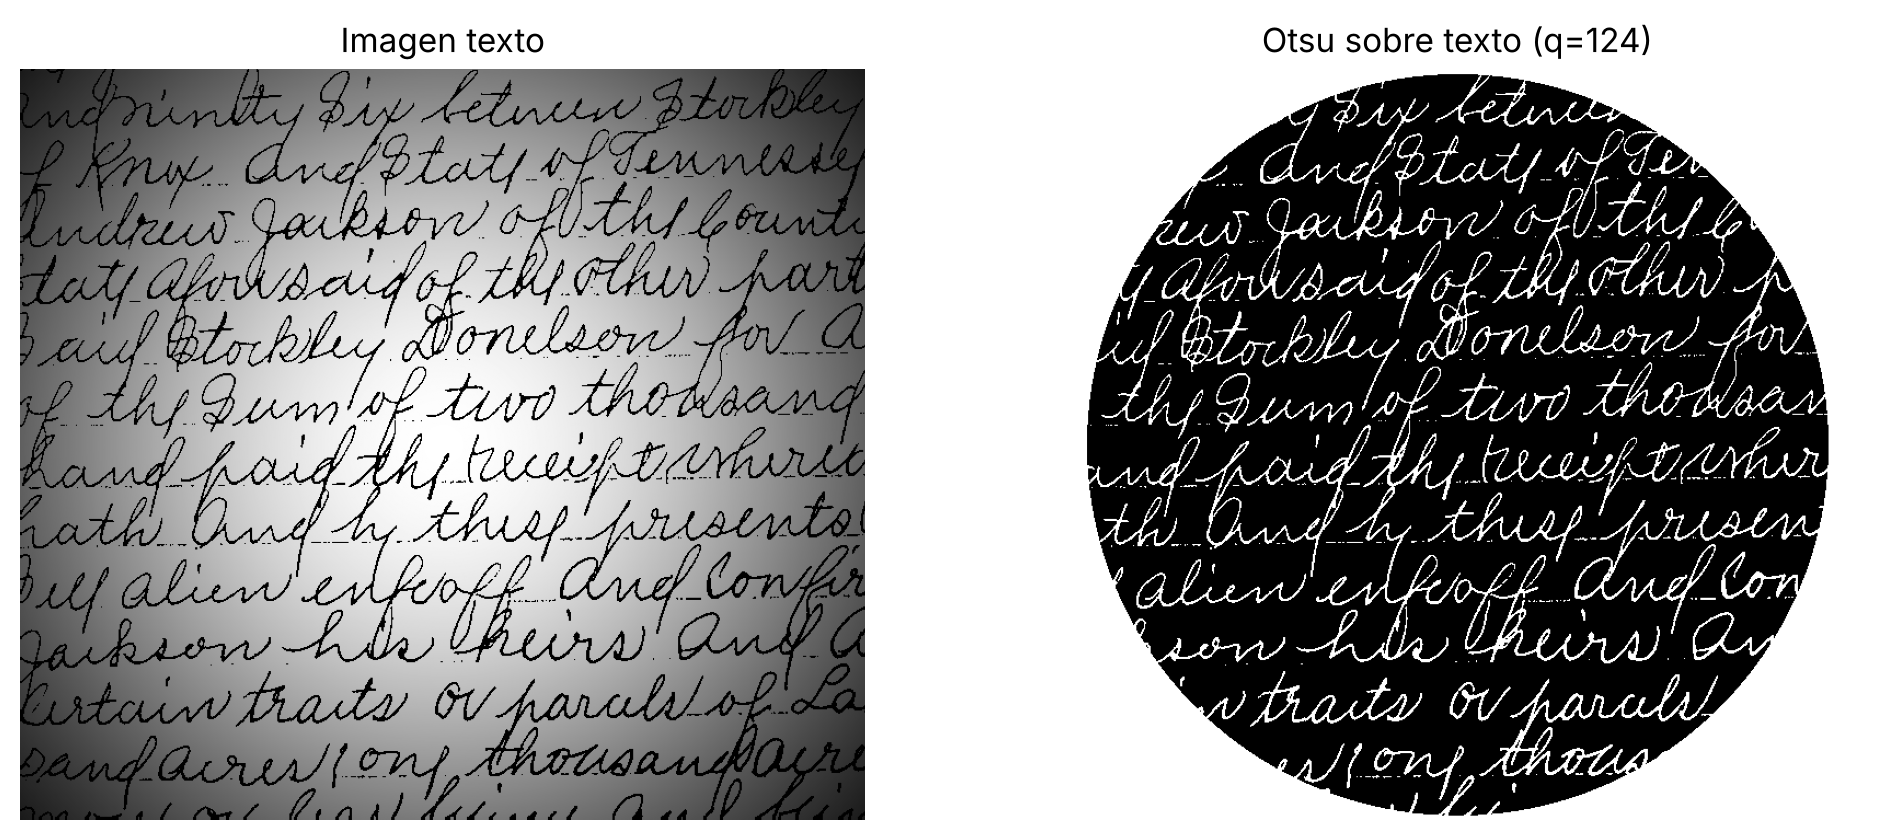

In [12]:
imagen = cv2.imread('images/texto.tif', 0)
texto_umbralizada, q = otsu(imagen, devolver_umbral=True)
mostrar([imagen, texto_umbralizada], ['Imagen texto', f'Otsu sobre texto (q={q})'], tam=(12, 6))

**Otsu falla** porque la iluminación no es uniforme (centro muy claro, bordes oscuros): un único umbral global no sirve. En las esquinas el fondo es más oscuro que el umbral y se marca todo como "texto"; el resultado es un círculo.

**Umbralización variable:** cada píxel se compara con un umbral calculado con **sus vecinos** ($a\sigma + b\mu$ local), así el umbral "sigue" a la iluminación.

Dos formas de programarla:
1. **Bucles** (lo que dice el enunciado, fácil de entender, lento).
2. **Vectorizada**: la media local es un filtro de la media (`cv2.blur`), y la desviación sale de $\sigma^2 = E[x^2] - (E[x])^2$, o sea `blur(img²) - blur(img)²`. Igual que un filtro, pero no lineal.

In [13]:
def variable(imagen, a=1.0, b=0.5, tam=3):
    """Versión vectorizada (rápida)."""
    f = imagen.astype(np.float64)                        # ¡float! en uint8 img*img desborda
    mu = cv2.blur(f, (tam, tam))                          # media local
    var = cv2.blur(f * f, (tam, tam)) - mu ** 2           # E[x^2] - E[x]^2
    sigma = np.sqrt(np.maximum(var, 0))                   # max(.,0) por errores de redondeo
    g = (f < a * sigma + b * mu).astype(np.uint8)         # 1 = texto (oscuro), 0 = fondo
    return g


def variable_bucles(imagen, a=1.0, b=0.5):
    """Versión con bucles, literal al algoritmo (ventana 3x3)."""
    f = np.pad(imagen.astype(np.float64), 1, mode='reflect')  # borde para que la ventana quepa
    filas, cols = imagen.shape
    g = np.zeros((filas, cols), np.uint8)
    for x in range(filas):
        for y in range(cols):
            ventana = f[x:x + 3, y:y + 3]          # 3x3 centrada en (x,y) de la imagen original
            mu, sigma = ventana.mean(), ventana.std()
            if imagen[x, y] < a * sigma + b * mu:
                g[x, y] = 1
    return g

Comprueba ahora que la umbralización variable funciona bien en este ejemplo concreto. Evidentemente, la fórmula elegida es ad-hoc para la imagen concreta, pero en función de la iluminación podríamos elegir otras condiciones del estilo 
$$imagen(x,y)<a \sigma_{x,y} + b \mu_{x,y}$$
siendo $a$ y $b$ dos números cualesquiera.

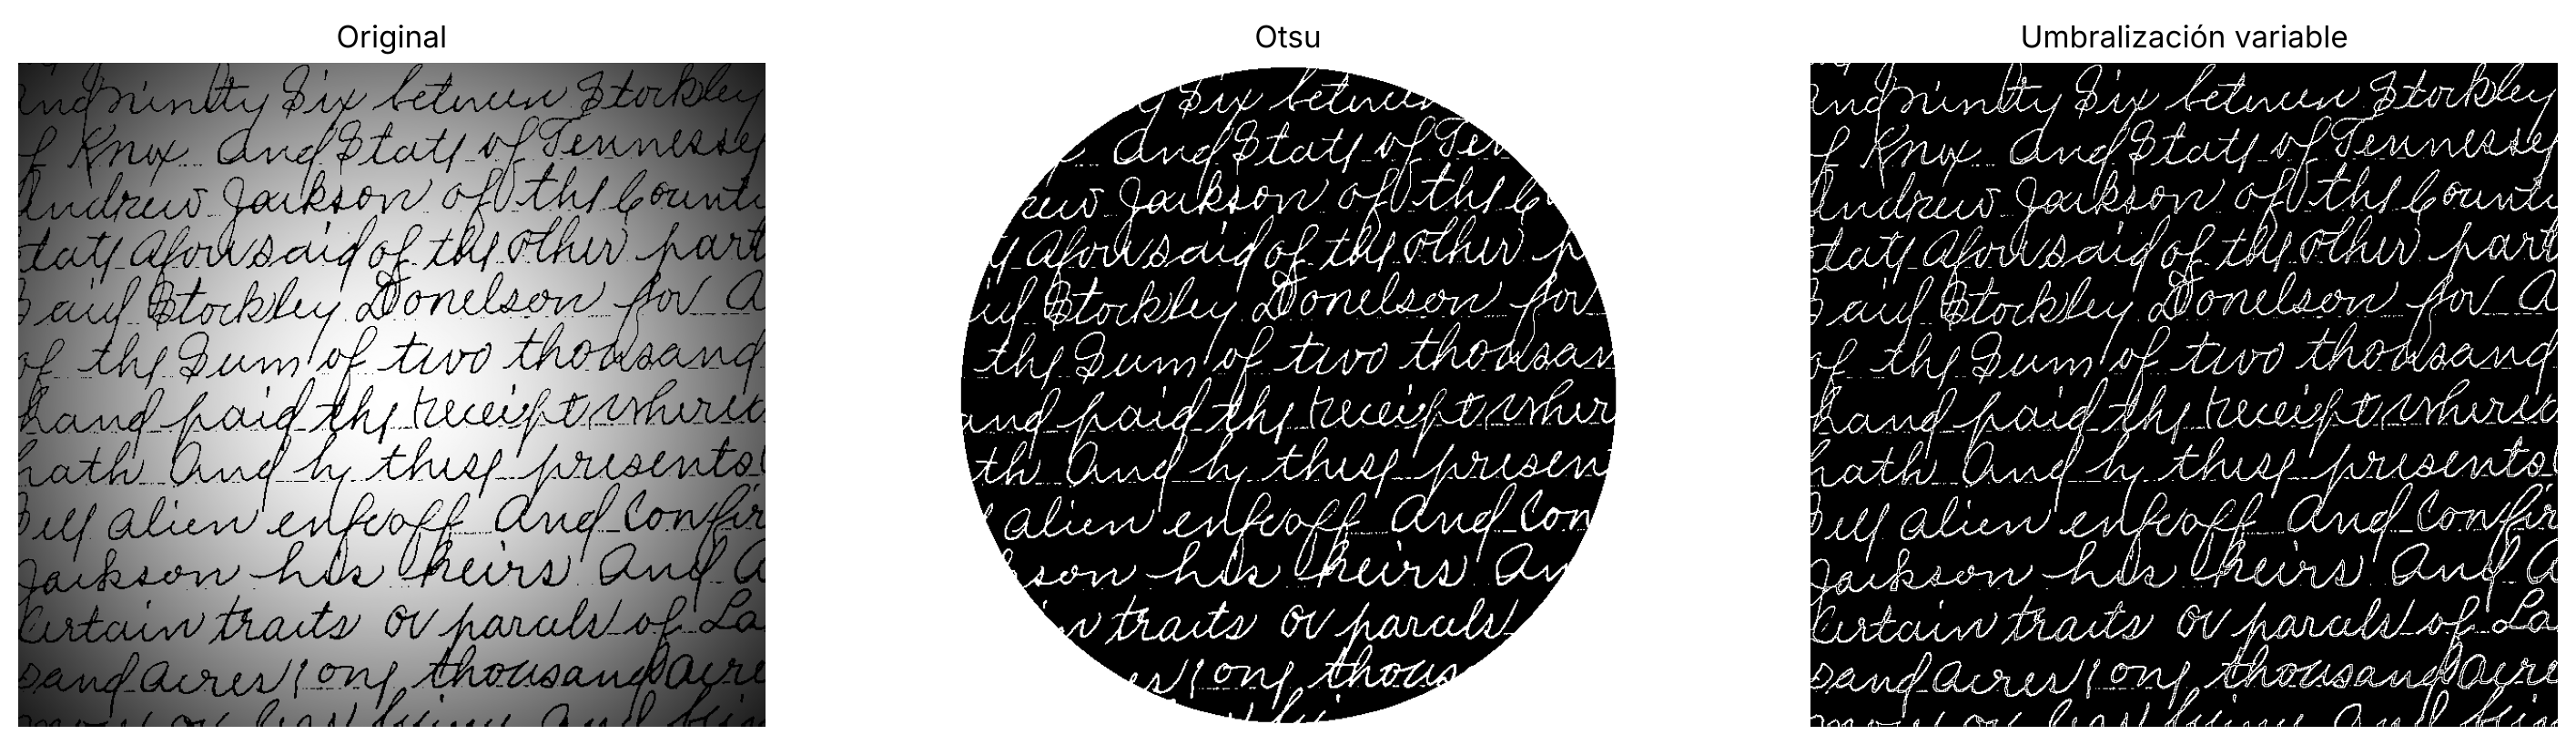

Píxeles distintos entre versión bucles y vectorizada: 0


In [14]:
imagen = cv2.imread('images/texto.tif', 0)
texto_umbralizada_2 = variable(imagen) * 255
mostrar([imagen, texto_umbralizada, texto_umbralizada_2],
        ['Original', 'Otsu', 'Umbralización variable'], tam=(18, 6))

# Comprobación: la versión con bucles da lo mismo (tarda unos segundos)
g_bucles = variable_bucles(imagen)
print('Píxeles distintos entre versión bucles y vectorizada:', np.sum(g_bucles != variable(imagen)))

Probamos otros valores de $a$ y $b$ para ver su efecto ($b$ controla cuánto por debajo de la media local tiene que estar un píxel; $a$ cuánto pesa el contraste local):

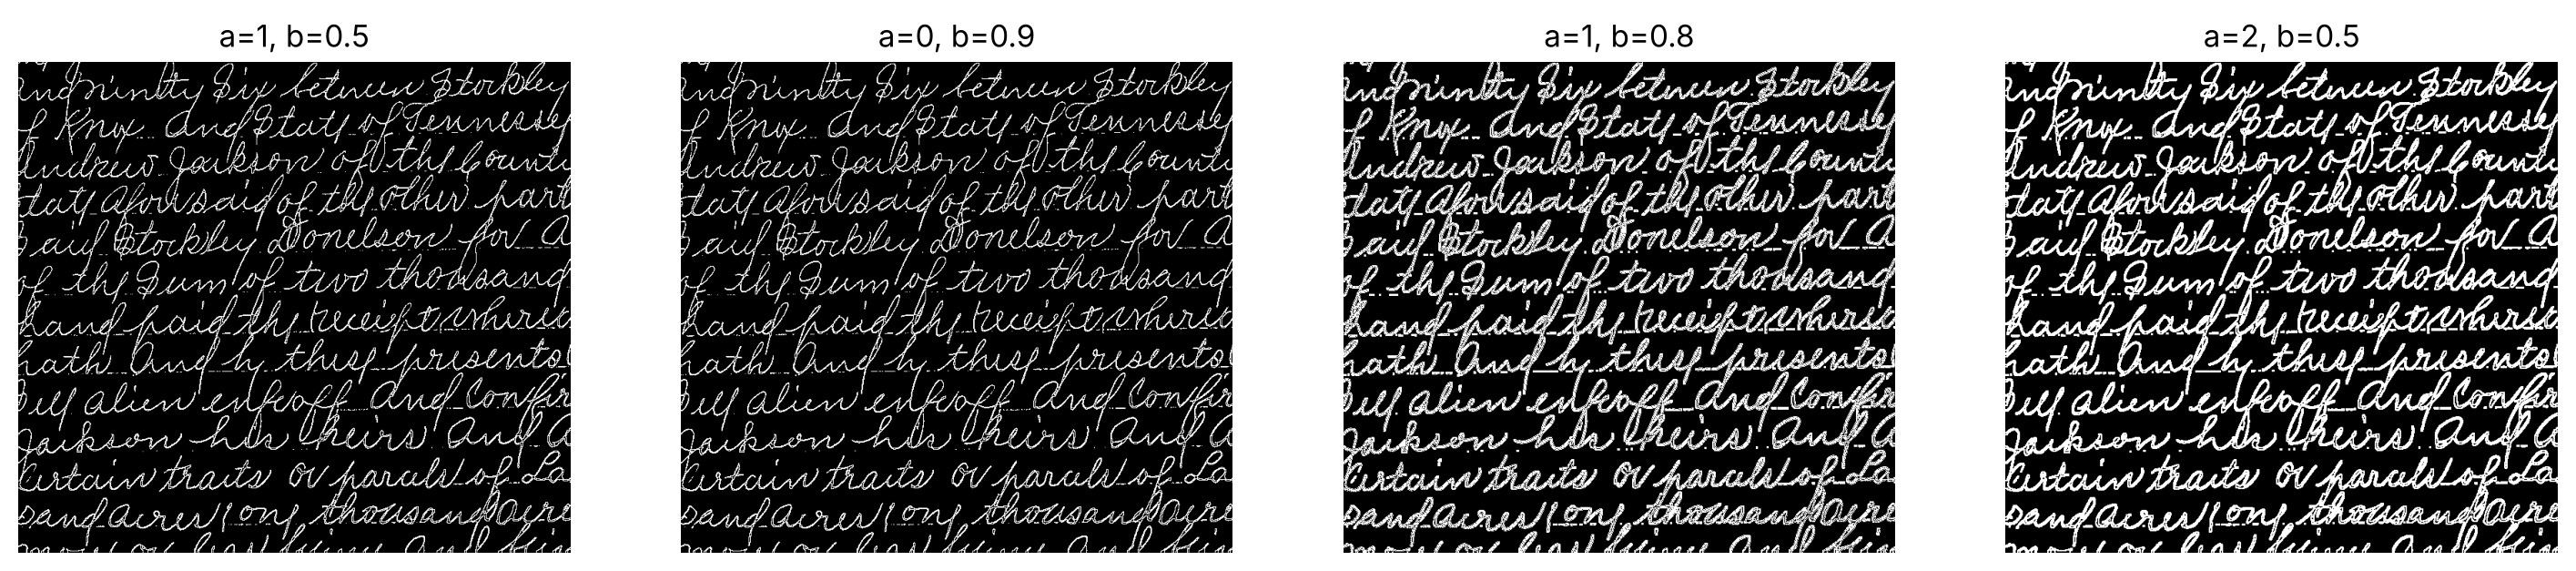

In [15]:
opciones = [(1, 0.5), (0, 0.9), (1, 0.8), (2, 0.5)]
mostrar([variable(imagen, a, b) * 255 for a, b in opciones],
        [f'a={a}, b={b}' for a, b in opciones], tam=(18, 5))

**Conclusiones:**
- Con $a=1, b=0.5$ el texto se segmenta bien en toda la imagen, independientemente de la iluminación.
- En zonas planas del fondo, $\sigma\approx0$ y el umbral es $0.5\mu$: el píxel tendría que ser la mitad de oscuro que sus vecinos → se queda como fondo. En los trazos (borde de la letra) $\sigma$ es grande y el umbral sube → se detecta texto.
- Subir $b$ (p. ej. 0.8–0.9) hace el umbral más permisivo y aparece ruido del fondo; bajarlo adelgaza/rompe los trazos. Los valores son *ad hoc* para cada imagen.